<a href="https://colab.research.google.com/github/berevai/METODOS-NUMERICOS/blob/main/M%C3%A9todo_de_Newton.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Método de Newton-Raphson.**
Para resolver ecuaciones no lineales hay varios métodos muy útiles:

*   Métodos Cerrados (o de intervalo)
*   Métodos Abiertos
*   Métodos Especiales para polinomios.

En este ejercicio utilizaremos un el tercer método visto en clase: **El Método de Newton-Raphson.**

A diferencia de los métodos cerrados, este no requiere que la función cambie de signo en los extremos, ahora, *necesitamos una buena aproximación inicial $p_0$ y que la función sea derivable*.

Pero específicamente el Método de Newton hace lo siguiente:

Sea $f \in C^2[a,b]$. Si $p_0 \in [a,b]$ es una aproximación a $p$ tal que $f(p) = 0$ y $f'(p_0) \neq 0$, entonces el polinomio de Taylor de primer orden alrededor de $p_0$ es:

$f(p) = f(p_0) + (p - p_0)f'(p_0) + \frac{(p - p_0)^2}{2}f''(\xi(p))$

Suponiendo que $|p - p_0|$ es pequeño, el término cuadrático es despreciable. Igualando a cero y despejando $p$, obtenemos la fórmula iterativa:

$p_n = p_{n-1} - \frac{f(p_{n-1})}{f'(p_{n-1})}, \quad \text{para } n \geq 1$

Es de convergencia rápida (cuadrática) si se elige bien $p_0$.


In [ ]:
# Importamos las librerías necesarias
import numpy as np
import matplotlib.pyplot as plt

Para probar el método, utilizaremos el Ejemplo 1 de la página 51 del libro de Burden.

Queremos resolver la ecuación:
$\cos(x) - x = 0$

En el intervalo $[0, \pi/2]$.

El libro nos sugiere usar como aproximación inicial $p_0 = \frac{\pi}{4} \approx 0.7853981635$.

Para aplicar el método, necesitamos la función y su derivada:
$f(x) = \cos(x) - x$,
$f'(x) = -\sin(x) - 1$

Por lo tanto, nuestra función de iteración es:
$p_n = p_{n-1} - \frac{\cos(p_{n-1}) - p_{n-1}}{-\sin(p_{n-1}) - 1}$

In [2]:
# Definimos la función f(x) y su derivada f'(x)
# Usamos funciones lambda para una sintaxis compacta y clara
f = lambda x: np.cos(x) - x
df = lambda x: -np.sin(x) - 1

Ahora implementaremos el Algoritmo 2.3 del libro de Burden.

El algoritmo sigue una secuencia de pasos iterativos:

1. Entrada: Aproximación inicial $p_0$, tolerancia $TOL$, máximo de iteraciones $N_0$.
2. Iteración: Calcular $p = p_0 - f(p_0)/f'(p_0)$.
3. Criterio de parada: Si $|p - p_0| < TOL$, el procedimiento fue exitoso.
4. Actualización: Si no se cumple, $p_0 = p$ y se repite.

A continuación, implementamos esto en una función de Python. Usamos un bloque try-except para capturar el caso en que la derivada sea cero, lo cual haría fallar el método.

In [4]:
def metodo_newton(f, df, p0, tol, max_iter):
    """
    Implementa el método de Newton-Raphson (Algoritmo 2.3).
    Retorna la raíz aproximada y un historial de iteraciones.
    """
    i = 1
    historial = []

    # Imprimimos encabezado de tabla
    print(f"{'Iter':<6} | {'p_n':<15} | {'f(p_n)':<15} | {'Error |p_n - p_{n-1}|':<20}")
    print("-" * 65)

    while i <= max_iter:
        # Evaluamos la derivada para evitar división por cero
        derivada = df(p0)
        if derivada == 0:
            print("Error: La derivada es cero. El método falla.")
            return None, historial

        # Paso 3: Calcular p_i
        p = p0 - f(p0) / derivada

        # Calcular error absoluto
        error = abs(p - p0)

        # Guardamos datos para la tabla
        historial.append({'Iter': i, 'p_n': p, 'f(p_n)': f(p), 'Error': error})

        # Imprimimos fila de la tabla
        print(f"{i:<6} | {p:<15.10f} | {f(p):<15.10e} | {error:<20.10e}")

        # Paso 4: Criterio de parada
        if error < tol:
            print("-" * 65)
            print(f"\n Procedimiento exitoso en {i} iteraciones.")
            print(f"Raíz aproximada p = {p:.10f}")
            return p, historial

        # Paso 5 y 6: Incrementar contador y actualizar p0
        i += 1
        p0 = p

    print("-" * 65)
    print(f" El método falló después de {max_iter} iteraciones.")
    return None, historial

Ejecutamos el algoritmo con los parámetros del Ejemplo 1:

· $p_0 = \pi/4$
· $TOL = 10^{-6}$
· $N_0 = 50$

Los resultados se mostrarán en una tabla formateada, similar a la Tabla 2.4 del libro.

In [5]:

# Definimos los parámetros de entrada
p0_inicial = np.pi / 4
tolerancia = 1e-6
max_iteraciones = 50

# Llamamos a la función
print("=" * 65)
print(" MÉTODO DE NEWTON ")
print("=" * 65)
raiz, historial = metodo_newton(f, df, p0_inicial, tolerancia, max_iteraciones)



 MÉTODO DE NEWTON 
Iter   | p_n             | f(p_n)          | Error |p_n - p_{n-1}|
-----------------------------------------------------------------
1      | 0.7395361335    | -7.5487468250e-04 | 4.5862029882e-02    
2      | 0.7390851781    | -7.5129866439e-08 | 4.5095540923e-04    
3      | 0.7390851332    | -7.7715611724e-16 | 4.4890849038e-08    
-----------------------------------------------------------------

 Procedimiento exitoso en 3 iteraciones.
Raíz aproximada p = 0.7390851332


La figura 2.7 de Burden ilustra cómo el método de Newton utiliza tangentes sucesivas.

Comenzando en $p_0$, la aproximación $p_1$ es la intersección con el eje $x$ de la recta tangente a la gráfica de $f$ en $(p_0, f(p_0))$.

La aproximación $p_2$ es la intersección con el eje $x$ de la recta tangente en $(p_1, f(p_1))$, y así sucesivamente.

Vamos a graficar la función, las tangentes y los puntos de iteración para visualizar la rápida convergencia.


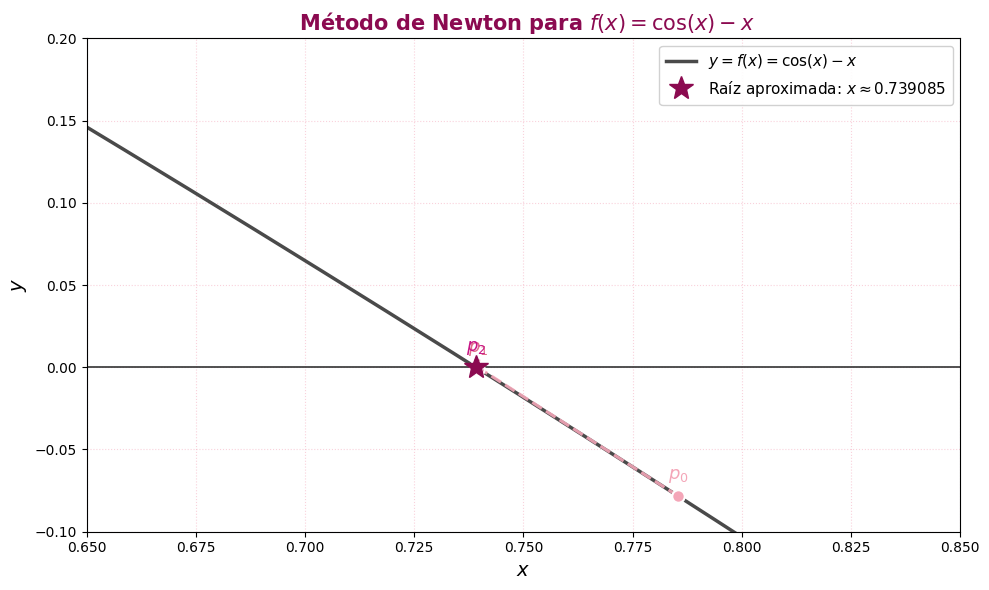

In [10]:
# 1. Definimos la función y su derivada
f = lambda x: np.cos(x) - x
df = lambda x: -np.sin(x) - 1

# 2. Calculamos los puntos de iteración (p0, p1, p2, p3)
p0 = np.pi / 4
puntos = [p0]
for _ in range(3): # Calculamos p1, p2, p3
    p_nuevo = puntos[-1] - f(puntos[-1]) / df(puntos[-1])
    puntos.append(p_nuevo)

# 3. Configuramos la figura
fig, ax = plt.subplots(figsize=(10, 6))

# 4. Graficamos la función f(x)
x_vals = np.linspace(0, 1.2, 400)
ax.plot(x_vals, f(x_vals), label=r'$y = f(x) = \cos(x) - x$', color='#4a4a4a', linewidth=2.5) # Gris oscuro para la curva principal

# 5. Graficamos el eje x (y=0)
ax.axhline(0, color='#333333', linewidth=1.2)

# 6. Dibujamos las tangentes y los puntos de iteración con tonos ROSAS
# Paleta de rosas: Rosa palo, Rosa coral, Rosa fucsia
colores_rosas = ['#f4a6b8', '#e06c8a', '#c71585']
etiquetas = [r'$p_0$', r'$p_1$', r'$p_2$']

for i in range(len(puntos)-1):
    p_actual = puntos[i]
    p_siguiente = puntos[i+1]

    # Punto en la curva
    ax.plot(p_actual, f(p_actual), 'o', color=colores_rosas[i], markersize=9, zorder=5, markeredgecolor='white', markeredgewidth=1.5)

    # Etiqueta del punto
    ax.annotate(etiquetas[i], (p_actual, f(p_actual)),
                 textcoords="offset points", xytext=(0, 12), ha='center',
                 fontsize=13, fontweight='bold', color=colores_rosas[i])

    # Línea tangente
    ax.plot([p_actual, p_siguiente], [f(p_actual), 0], '--',
             color=colores_rosas[i], linewidth=2.2, alpha=0.9)

    # Marca en el eje x para p_siguiente
    ax.plot(p_siguiente, 0, '|', color=colores_rosas[i], markersize=12, markeredgewidth=2.5)

# 7. Marcamos la raíz final
raiz = puntos[-1]
# Usamos un tono rosa muy oscuro o negro para la raíz final
ax.plot(raiz, 0, '*', color='#8b0a50', markersize=18, zorder=10, label=fr'Raíz aproximada: $x \approx {raiz:.6f}$')

# 8. Personalización de la gráfica
ax.set_title(r' Método de Newton para $f(x) = \cos(x) - x$', fontsize=15, fontweight='bold', color='#8b0a50')
ax.set_xlabel(r'$x$', fontsize=14)
ax.set_ylabel(r'$y$', fontsize=14)
ax.legend(loc='upper right', fontsize=11, framealpha=0.9)
ax.grid(True, linestyle=':', alpha=0.5, color='#f4a6b8') # Rejilla en rosa claro

#Zoom en la zona de convergencia
ax.set_xlim(0.65, 0.85)
ax.set_ylim(-0.1, 0.2)

plt.tight_layout()
plt.show()

**Solución Final:** La raíz aproximada de $f(x) = \cos(x) - x$ es $x \approx 0.7390851332$.

*Observaciones:*

1. Como se puede ver en la tabla, el error se reduce drásticamente en cada iteración. Para la iteración 4, el error es del orden de
 $10^{-10}$, lo que indica que hemos alcanzado la precisión de la máquina.

2. El método de Newton requirió solo 4 iteraciones para converger a la solución con una tolerancia de $10^{-6}$. Esto es significativamente más rápido que el método de bisección.

3. Elección de $p_0$: La convergencia rápida se debe a que la aproximación inicial $p_0 = \pi/4$ está lo suficientemente cerca de la raíz real y a que $f'(x) \neq 0$ en las cercanías.
